# Acoustic TCN — HUSTmotor | UTC Project Workshop **Université de technologie de Compiègne (UTC)** · Acoustic-only motor fault classification · Research prototype

**Question:** Can a compact Temporal Convolutional Network (TCN), with dilated residual convolutions, improve fault classification on an unseen motor speed compared with our original 1D CNN (48.45% overall)?

**Recommended sequence:** Sections 1–10 (smoke test), 11 (source-speed folds),12 (review); only then enable the 40-run benchmark in Section 13. GPU recommended. Never use actual target-domain results to choose settings.

Baseline: [Original acoustic CNN](https://github.com/Sofianopoulou/hustmotor-acoustic-fault-diagnosis/blob/main/notebooks/HUSTmotor_Acoustic_Baseline.ipynb). Preprocessing: [Genti's repository](https://github.com/Genti24-bit/ISCF_Project).

## 1. The idea, in plain English
A regular CNN slides small filters over the waveform. A **TCN** uses *dilation*: its filters skip increasingly larger gaps (1, 2, 4, 8, …), so patterns farther apart can influence an output. **Residual connections** keep a shortcut around every block. The classifier makes **one prediction per 1,024-point window**, so we choose **noncausal symmetric padding**, not forecasting-style causal padding.

**Limitation:** 1,024 samples at 25.6 kHz = **40 ms**. No architecture can infer the complete 200 ms cycle of a 5 Hz revolution from one isolated 40 ms window. Longer-window experiments require the original recordings.

**Normalization:** Use Genti's **per-window Z-score**, because our original CNN with Z-score averaged 48.45%, versus 38.19% with RMS scaling. That is a fair initial architectural comparison, not proof Z-score is always best.

**Proposed network:** Conv1D stem (1→32, kernel 15) → 7 residual blocks (32 channels; each has two kernel-3 convolutions; dilations 1, 2, 4, 8, 16, 32, 64) → global average pooling → 6 logits. With no striding, receptive field = `1 + (15−1) + 2*(3−1)*sum(dilations) = 523` samples ≈ 20.43 ms. The classifier pools information over the entire 1,024 samples, although any one final location sees ~523 points.

## 2. Experiment plan and safeguards

- **Data:** Genti HUSTmotor v1.3, validated SHA-256. Waveform arrays `ac` are already per-window Z-scored. Labels `y`; speeds `domain`; acquisition-block split `split`.
- **Task 9/10/11/12:** actual held-out speed 5/10/20/30 Hz respectively.
- **Source-speed audit:** for each task, train on two other speeds (`split==0`), validate on the remaining source speed (`split==1`). Never include the actual target in either set.
- **Full benchmark:** source train = 14,400 (`split==0` at 3 speeds); source validation = 3,600 (`split==1` at those same speeds); target test = 1,200 (`split==1` at withheld speed). Save the best epoch on *source validation only*.
- **Fairness:** 50 epochs, Adam, initial LR 5e-4, batch 256, same decay schedule, 10 seeds for final testing. 40 models if enabled. Different architectures inherently have different parameter counts/inductive biases.
- **Interpretation:** existing target speed results have previously been inspected, so this is an exploratory comparison, not a fresh blind confirmation.

In [1]:
# Colab Drive directories; no checkpoints will be overwritten silently.
from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')
ROOT = Path('/content/drive/MyDrive/HUSTmotor_Acoustic_TCN_UTC')
DATA_DIR = ROOT/'data'; MODEL_DIR = ROOT/'models'; RESULTS_DIR = ROOT/'results'; FIG_DIR = ROOT/'figures'
for d in (DATA_DIR,MODEL_DIR,RESULTS_DIR,FIG_DIR): d.mkdir(parents=True, exist_ok=True)
print('Experiment output:',ROOT)

Mounted at /content/drive
Experiment output: /content/drive/MyDrive/HUSTmotor_Acoustic_TCN_UTC


## 3. Run switches — start with smoke test and source-speed audit
The default **does not** run 40 final trainings. After checking Sections 10–12, set `RUN_FULL_BENCHMARK=True` and rerun the configuration and full-run sections. Existing matching checkpoints are reused when possible.

In [2]:
RUN_SMOKE_TEST = False
RUN_SOURCE_SPEED_AUDIT = False

SOURCE_TASKS = (9,)
SOURCE_SEEDS = (0, 1, 2)
SOURCE_EPOCHS = 20

RUN_FULL_BENCHMARK = True

FULL_TASKS = (9, 10, 11, 12)
FULL_SEEDS = tuple(range(10))

REUSE_MATCHING_CHECKPOINTS = True
EXPORT_FULL_PREDICTIONS = True

NORM = 'zscore'
BATCH_SIZE = 256
FULL_EPOCHS = 50
BASE_LR = 5e-4
WIDTH = 32
DILATIONS = (1,2,4,8,16,32,64)
KERNEL = 3
DROPOUT = 0.10
ARCH_ID = 'TCN_noncausal_w32_k3_d1-64_2conv_GAP_v1'
TASK_TO_DOMAIN = {9:0,10:1,11:2,12:3}
SPEED_HZ = {0:5,1:10,2:20,3:30}
CLASS_NAMES = ['Healthy','Bearing fault','Bowed rotor','Broken rotor bars','Rotor misalignment','Voltage unbalance']
print('First-stage audit:',RUN_SOURCE_SPEED_AUDIT, 'Final 40-run study:',RUN_FULL_BENCHMARK)

First-stage audit: False Final 40-run study: True


## 4. Imports and reproducibility

In [3]:
import os, hashlib, json, random, subprocess, sys, time
from copy import deepcopy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader,TensorDataset
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:',torch.__version__,'Device:',DEVICE)
def set_seed(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic=True;torch.backends.cudnn.benchmark=False

def file_sha(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for b in iter(lambda:f.read(1024*1024),b''):h.update(b)
    return h.hexdigest()

PyTorch: 2.14.1+cu130 Device: cuda


## 5. Retrieve the verified v1.3 archive
`hustmotor_1024_v1.3.npz` includes 24,000 aligned acoustic/vibration windows, speed labels and block-level split metadata. If you have already downloaded it in another project, you can copy it into this notebook's `data` folder to avoid repeated downloads.

In [4]:
import requests
DATA_PATH=DATA_DIR/'hustmotor_1024_v1.3.npz'
EXPECTED_SHA='605a041d35aab9a12749d9f5f45580cca87e0b5b63b8330bcafdb215da3a8e7d'
URL='https://github.com/Genti24-bit/ISCF_Project/releases/download/v1.3/hustmotor_1024_v1.3.npz'
if not DATA_PATH.exists() or file_sha(DATA_PATH)!=EXPECTED_SHA:
    print('Downloading verified dataset...')
    tmp=DATA_PATH.with_suffix('.download')
    with requests.get(URL,stream=True,timeout=90) as res:
        res.raise_for_status()
        with open(tmp,'wb') as f:
            for chunk in res.iter_content(1024*1024):
                if chunk:f.write(chunk)
    if file_sha(tmp)!=EXPECTED_SHA:
        tmp.unlink(missing_ok=True);raise ValueError('Download checksum mismatch; stop.')
    tmp.replace(DATA_PATH)
assert file_sha(DATA_PATH)==EXPECTED_SHA
print('Verified:',DATA_PATH, 'size', round(DATA_PATH.stat().st_size/1e6,1),'MB')

Verified: /content/drive/MyDrive/HUSTmotor_Acoustic_TCN_UTC/data/hustmotor_1024_v1.3.npz size 199.4 MB


## 6. Load Z-score acoustic windows + alignment metadata
Unlike RMS, this study directly uses the already Z-scored `ac` array. **Do not Z-score it again.** We use `domain` and `split` to construct disjoint training/validation/test partitions; the global original array index is retained for prediction exports.

In [5]:
with np.load(DATA_PATH,allow_pickle=False) as z:
    print('Available arrays:',z.files)
    X=np.asarray(z['ac'],dtype=np.float32)
    Y=np.asarray(z['y'],dtype=np.int64)
    DOMAIN=np.asarray(z['domain'],dtype=np.int64)
    SPLIT=np.asarray(z['split'],dtype=np.int64)
    BLOCK=np.asarray(z['block'],dtype=np.int64)
    START=np.asarray(z['start'],dtype=np.int64)
    RMS_A=np.asarray(z['rms_a'],dtype=np.float32)
    RMS_V=np.asarray(z['rms_v'],dtype=np.float32)
assert X.shape==(24000,1024)
assert Y.shape==DOMAIN.shape==SPLIT.shape==BLOCK.shape==START.shape==(24000,)
assert set(np.unique(DOMAIN))==set(range(4))
assert set(np.unique(SPLIT))=={0,1}
assert np.isfinite(X).all()
print('Window shapes:',X.shape,'Classes:',np.bincount(Y),'source/test counts:',np.bincount(SPLIT))
print('Mean window mean/std:',np.mean(X.mean(axis=1)),np.mean(X.std(axis=1)))

Available arrays: ['vib', 'ac', 'y', 'domain', 'block', 'win', 'split', 'rms_v', 'rms_a', 'dc_v', 'dc_a', 'start', 'feat_v', 'feat_a', 'feat_names', 'classes', 'domains', 'meta']
Window shapes: (24000, 1024) Classes: [4000 4000 4000 4000 4000 4000] source/test counts: [19200  4800]
Mean window mean/std: 1.2521438e-10 1.0


## 7. Build source-held-speed folds and full leave-one-speed-out partitions
The source-speed audit uses `split=0` from two source speeds to train, `split=1` from the third source speed to validate. The actual target speed is excluded from that fold entirely.

In [6]:
def source_folds(task):
    target=TASK_TO_DOMAIN[task]
    sources=[d for d in range(4) if d!=target]
    for held in sources:
        train_speeds=[d for d in sources if d!=held]
        tr=np.flatnonzero((SPLIT==0)&np.isin(DOMAIN,train_speeds))
        va=np.flatnonzero((SPLIT==1)&(DOMAIN==held))
        assert len(tr)==9600 and len(va)==1200
        assert not np.any(DOMAIN[tr]==target) and not np.any(DOMAIN[va]==target)
        assert not np.intersect1d(tr,va).size
        yield held,tr,va

def full_parts(task):
    target=TASK_TO_DOMAIN[task]
    tr=np.flatnonzero((DOMAIN!=target)&(SPLIT==0))
    va=np.flatnonzero((DOMAIN!=target)&(SPLIT==1))
    te=np.flatnonzero((DOMAIN==target)&(SPLIT==1))
    assert (len(tr),len(va),len(te))==(14400,3600,1200)
    assert not np.intersect1d(tr,va).size and not np.intersect1d(tr,te).size
    assert not np.intersect1d(va,te).size
    return tr,va,te
rows=[]
for task in FULL_TASKS:
    for held,tr,va in source_folds(task):
        rows.append(dict(task=task,target_hz=SPEED_HZ[TASK_TO_DOMAIN[task]],train_hz='/'.join(map(str,sorted({SPEED_HZ[d] for d in DOMAIN[tr]}))),held_source_hz=SPEED_HZ[held],train_windows=len(tr),val_windows=len(va)))
display(pd.DataFrame(rows))

,task,target_hz,train_hz,held_source_hz,train_windows,val_windows
0,9,5,20/30,10,9600,1200
1,9,5,10/30,20,9600,1200
2,9,5,10/20,30,9600,1200
3,10,10,20/30,5,9600,1200
4,10,10,5/30,20,9600,1200
5,10,10,5/20,30,9600,1200
6,11,20,10/30,5,9600,1200
7,11,20,5/30,10,9600,1200
8,11,20,5/10,30,9600,1200
9,12,30,10/20,5,9600,1200


## 8. Define the compact TCN
Each block computes two dilated 1D convolutions with ReLU and dropout and adds the original input (residual shortcut). We use symmetrical padding to preserve sequence length. There is **no attention, pretrained encoder or SupCon** here, so the model directly tests a temporal convolutional architecture.

The final pooling layer averages each of 32 feature channels over time and the classifier outputs six **logits**. `CrossEntropyLoss` expects raw logits, not softmax probabilities.

In [7]:
class TemporalResidualBlock(nn.Module):
    def __init__(self,channels,dilation,kernel=3,dropout=0.10):
        super().__init__()
        assert (kernel-1)*dilation%2==0, 'Need integer symmetric padding'
        pad=(kernel-1)*dilation//2
        self.net=nn.Sequential(
            nn.Conv1d(channels,channels,kernel_size=kernel,dilation=dilation,padding=pad,bias=False),
            nn.BatchNorm1d(channels),nn.ReLU(),nn.Dropout1d(dropout),
            nn.Conv1d(channels,channels,kernel_size=kernel,dilation=dilation,padding=pad,bias=False),
            nn.BatchNorm1d(channels),nn.Dropout1d(dropout)
        )
        self.act=nn.ReLU()
    def forward(self,x):
        return self.act(x+self.net(x))

class AcousticTCN(nn.Module):
    def __init__(self,width=WIDTH,dilations=DILATIONS,kernel=KERNEL,dropout=DROPOUT):
        super().__init__()
        self.stem=nn.Sequential(nn.Conv1d(1,width,kernel_size=15,padding=7,bias=False),nn.BatchNorm1d(width),nn.ReLU())
        self.blocks=nn.Sequential(*(TemporalResidualBlock(width,d,kernel,dropout) for d in dilations))
        self.pool=nn.AdaptiveAvgPool1d(1)
        self.fc=nn.Linear(width,6)
    def forward(self,x):
        z=self.blocks(self.stem(x))
        return self.fc(self.pool(z).squeeze(-1))

RF=1+14+2*(KERNEL-1)*sum(DILATIONS)
net=AcousticTCN().to(DEVICE)
with torch.no_grad():
    net.eval()
    out=net(torch.zeros(2,1,1024,device=DEVICE))
assert out.shape==(2,6)
print('Output:',out.shape,'Parameters:',sum(t.numel() for t in net.parameters()))
print('Theoretical receptive field:',RF,'samples;',round(RF/25600*1000,2),'ms')

Output: torch.Size([2, 6]) Parameters: 44646
Theoretical receptive field: 523 samples; 20.43 ms


## 9. Training and evaluation functions
Training matches the original acoustic CNN: Adam, CrossEntropyLoss, 50 epochs for the final study, batch size 256, and the original decay `lr=0.0005/(1+10p)^0.75`. The best epoch is chosen by **the specified source validation set**. A different source-validation fold is used during the preliminary audit.

**Caution:** A TCN with different model capacity, dropout and pooling is not a pure *dilation-only* ablation.

In [8]:
def make_loader(idx,shuffle=False,seed=0):
    data=TensorDataset(torch.from_numpy(X[idx]).unsqueeze(1),torch.from_numpy(Y[idx]))
    gen=torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(data,batch_size=BATCH_SIZE,shuffle=shuffle,generator=gen,
                      num_workers=0,pin_memory=(DEVICE.type=='cuda'))

def lr_at(epoch,epochs):
    return BASE_LR/(1+10*(epoch/epochs))**0.75

@torch.no_grad()
def evaluate(model,idx,include_predictions=False):
    model.eval(); preds=[];trues=[];losses=0.;n=0
    loss_fn=nn.CrossEntropyLoss()
    for xb,yb in make_loader(idx,shuffle=False):
        xb=xb.to(DEVICE);yb=yb.to(DEVICE)
        logits=model(xb)
        losses+=loss_fn(logits,yb).item()*len(yb);n+=len(yb)
        preds.append(logits.argmax(dim=1).cpu().numpy());trues.append(yb.cpu().numpy())
    p=np.concatenate(preds);y=np.concatenate(trues)
    result={'accuracy':accuracy_score(y,p),'macro_f1':f1_score(y,p,average='macro',zero_division=0),'loss':losses/n}
    if include_predictions:result.update(y_true=y,y_pred=p)
    return result

def train_model(tr_idx,val_idx,seed,epochs,verbose=False):
    set_seed(seed)
    model=AcousticTCN().to(DEVICE)
    loss_fn=nn.CrossEntropyLoss()
    opt=torch.optim.Adam(model.parameters(),lr=BASE_LR)
    best_acc=-1.;best_state=None;best_epoch=None;history=[]
    loader=make_loader(tr_idx,shuffle=True,seed=seed)
    for epoch in range(epochs):
        lr=lr_at(epoch,epochs)
        for g in opt.param_groups:g['lr']=lr
        model.train();total=0;correct=0;loss_total=0.
        for xb,yb in loader:
            xb=xb.to(DEVICE);yb=yb.to(DEVICE)
            opt.zero_grad(set_to_none=True)
            logits=model(xb);loss=loss_fn(logits,yb)
            loss.backward();opt.step()
            correct+=(logits.argmax(1)==yb).sum().item()
            loss_total+=loss.item()*len(yb);total+=len(yb)
        val=evaluate(model,val_idx)
        history.append(dict(epoch=epoch+1,train_acc=correct/total,train_loss=loss_total/total,
                            val_acc=val['accuracy'],val_macro_f1=val['macro_f1'],val_loss=val['loss'],lr=lr))
        if val['accuracy']>best_acc:
            best_acc=val['accuracy'];best_epoch=epoch+1;best_state=deepcopy(model.state_dict())
        if verbose and (epoch==0 or (epoch+1)%5==0 or epoch+1==epochs):
            print(f'epoch {epoch+1}/{epochs}: train {correct/total:.3f} val {val["accuracy"]:.3f} source-F1 {val["macro_f1"]:.3f}')
    model.load_state_dict(best_state)
    return model,pd.DataFrame(history),best_epoch,best_acc

## 10. Smoke test — two epochs (not a scientific result)
This verifies shape compatibility, forward pass, gradients, validation, and saving before any full training.

In [9]:
if RUN_SMOKE_TEST:
    tr,va,_=full_parts(9)
    smoke_model,smoke_history,smoke_epoch,smoke_val=train_model(tr,va,seed=0,epochs=2,verbose=True)
    display(smoke_history)
    print('PASS: smoke test finished; it is not a reported benchmark.')
else:print('Smoke test disabled')

Smoke test disabled


## 11. Source-only cross-speed audit — experiment before the full benchmark
Default: **Task 9, one seed, three source-held-speed folds, 15 epochs each**. It deliberately does *not* evaluate the real 5 Hz target.

These 15-epoch models are diagnostic only. They should **not** be compared directly to the 50-epoch, three-source-speed original CNN's 48.45%. When comparing against our existing 20-epoch audit, rerun the same epochs and splits on both architectures.

In [10]:
AUDIT_CSV=RESULTS_DIR/'tcn_source_speed_audit.csv'
if RUN_SOURCE_SPEED_AUDIT:
    audit_rows=[]
    for task in SOURCE_TASKS:
        for held,tr,va in source_folds(task):
            for seed in SOURCE_SEEDS:
                print('Audit task',task,'held source',SPEED_HZ[held],'Hz','seed',seed)
                model,hist,epoch,best=train_model(tr,va,seed,epochs=SOURCE_EPOCHS,verbose=False)
                result=evaluate(model,va)
                audit_rows.append(dict(task=task,actual_target_hz=SPEED_HZ[TASK_TO_DOMAIN[task]],
                                       held_source_hz=SPEED_HZ[held],seed=seed,epochs=SOURCE_EPOCHS,
                                       source_macro_f1=result['macro_f1'],source_accuracy_pct=100*result['accuracy'],
                                       best_epoch=epoch,architecture=ARCH_ID))
                pd.DataFrame(audit_rows).to_csv(AUDIT_CSV,index=False)
    display(pd.DataFrame(audit_rows).round(4))
    print('Saved:',AUDIT_CSV)
else:
    print('Audit training disabled; reading existing results if any.')
    if AUDIT_CSV.exists():display(pd.read_csv(AUDIT_CSV).round(4))

Audit training disabled; reading existing results if any.


,task,actual_target_hz,held_source_hz,seed,epochs,source_macro_f1,source_accuracy_pct,best_epoch,architecture
0,9,5,10,0,20,0.2637,34.1667,20,TCN_noncausal_w32_k3_d1-64_2conv_GAP_v1
1,9,5,10,1,20,0.2256,32.1667,18,TCN_noncausal_w32_k3_d1-64_2conv_GAP_v1
2,9,5,10,2,20,0.2365,31.9167,18,TCN_noncausal_w32_k3_d1-64_2conv_GAP_v1
3,9,5,20,0,20,0.7761,80.9167,20,TCN_noncausal_w32_k3_d1-64_2conv_GAP_v1
4,9,5,20,1,20,0.6321,66.8333,19,TCN_noncausal_w32_k3_d1-64_2conv_GAP_v1
5,9,5,20,2,20,0.5948,64.5833,20,TCN_noncausal_w32_k3_d1-64_2conv_GAP_v1
6,9,5,30,0,20,0.4089,44.5000,18,TCN_noncausal_w32_k3_d1-64_2conv_GAP_v1
7,9,5,30,1,20,0.4567,50.5833,14,TCN_noncausal_w32_k3_d1-64_2conv_GAP_v1
8,9,5,30,2,20,0.4261,46.1667,11,TCN_noncausal_w32_k3_d1-64_2conv_GAP_v1


## 12. Inspect source-speed performance and decide what to test next
Compare **macro-F1 across each held source speed** and note particularly weak folds. Do not optimize settings based on the unseen target speeds. Consider testing only a few source-validated hyperparameter variants (e.g. dilation depth or dropout) if the initial configuration is weak. A proper matched CNN audit would use the *same folds, seeds, epoch budget, checkpoint criterion* and sample preprocessing.

,task,held_source_hz,source_accuracy_pct,source_macro_f1
0,9,10,32.750,0.242
1,9,20,70.778,0.668
2,9,30,47.083,0.431


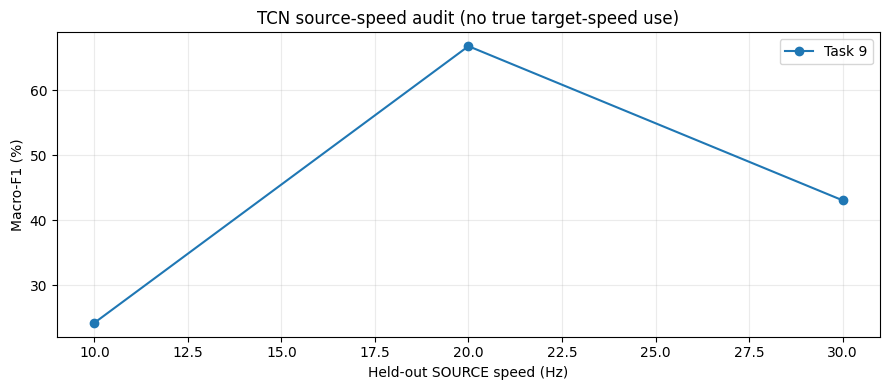

In [11]:
if AUDIT_CSV.exists():
    audit=pd.read_csv(AUDIT_CSV)
    grouped=audit.groupby(['task','held_source_hz'],as_index=False)[['source_accuracy_pct','source_macro_f1']].mean()
    display(grouped.round(3))
    fig,ax=plt.subplots(figsize=(9,4))
    for task,part in grouped.groupby('task'):
        ax.plot(part['held_source_hz'],100*part['source_macro_f1'],marker='o',label=f'Task {task}')
    ax.set(xlabel='Held-out SOURCE speed (Hz)',ylabel='Macro-F1 (%)',title='TCN source-speed audit (no true target-speed use)')
    ax.grid(alpha=.25);ax.legend();fig.tight_layout()
    fig.savefig(FIG_DIR/'tcn_source_audit_macro_f1.png',dpi=180);plt.show()
else:print('No source audit CSV yet')

## 13. OPTIONAL: final 4-task × 10-seed benchmark
**Only enable after source-only validation.** The 40 final models use all three source speeds for training, choose the best checkpoint using source validation, and report target accuracy. The `RUN_FULL_BENCHMARK` switch is `False` by default.

All matching checkpoints are reused. If the architecture or training configuration changes, choose a new `ARCH_ID` / output directory rather than silently mixing results. For full comparability, keep the same original 1,024-point Z-score normalization and source block splits.

In [12]:
FULL_CSV=RESULTS_DIR/'tcn_target_10runs_raw.csv'
def checkpoint_path(task,seed):return MODEL_DIR/f'tcn_task{task}_seed{seed}.pt'
def config(task,seed):
    return dict(task=task,seed=seed,architecture=ARCH_ID,dataset_sha256=EXPECTED_SHA,
                norm=NORM,epochs=FULL_EPOCHS,batch_size=BATCH_SIZE,base_lr=BASE_LR,
                width=WIDTH,dilations=list(DILATIONS),kernel=KERNEL,dropout=DROPOUT,
                model_selection='highest_source_validation_accuracy')

def get_checkpoint(task,seed):
    path=checkpoint_path(task,seed)
    if not path.exists():return None
    ck=torch.load(path,map_location='cpu',weights_only=False)
    for key,value in config(task,seed).items():
        if ck.get(key)!=value:raise ValueError(f'Mismatched checkpoint: {path} key={key}')
    return ck

if RUN_FULL_BENCHMARK:
    completed={}
    if FULL_CSV.exists():
        for row in pd.read_csv(FULL_CSV).to_dict('records'):
            completed[(int(row['task']),int(row['seed']))]=row
    for task in FULL_TASKS:
        tr,va,te=full_parts(task)
        for seed in FULL_SEEDS:
            old=get_checkpoint(task,seed) if REUSE_MATCHING_CHECKPOINTS else None
            if old is not None:
                model=AcousticTCN().to(DEVICE)
                model.load_state_dict(old['model_state_dict'])
                best_epoch=old['best_epoch'];best_val=old['best_val_acc']
                print('Reusing task',task,'seed',seed)
            else:
                if checkpoint_path(task,seed).exists():
                    raise FileExistsError('Existing checkpoint not matched; refusing overwrite')
                model,hist,best_epoch,best_val=train_model(tr,va,seed,FULL_EPOCHS)
                torch.save({**config(task,seed), 'best_epoch':best_epoch,
                            'best_val_acc':best_val,'model_state_dict':model.state_dict()},checkpoint_path(task,seed))
                hist.to_csv(RESULTS_DIR/f'tcn_history_task{task}_seed{seed}.csv',index=False)
            target=evaluate(model,te,include_predictions=EXPORT_FULL_PREDICTIONS)
            completed[(task,seed)]=dict(task=task,seed=seed,target_hz=SPEED_HZ[TASK_TO_DOMAIN[task]],
                target_acc_pct=100*target['accuracy'],target_macro_f1=target['macro_f1'],
                best_epoch=best_epoch,source_val_pct=100*best_val)
            pd.DataFrame(list(completed.values())).sort_values(['task','seed']).to_csv(FULL_CSV,index=False)
            if EXPORT_FULL_PREDICTIONS:
                df=pd.DataFrame(dict(index=te,task=task,run=seed+1,true=target['y_true'],pred=target['y_pred'],
                       speed_hz=SPEED_HZ[TASK_TO_DOMAIN[task]],class_code=target['y_true'],
                       block=BLOCK[te],start=START[te],rms_a=RMS_A[te],rms_v=RMS_V[te]))
                df['win']=np.asarray(np.load(DATA_PATH)['win'])[te]
                df.to_csv(RESULTS_DIR/f'tcn_predictions_task{task}_seed{seed}.csv',index=False)
            print(f'Task {task}, seed {seed}: target {100*target["accuracy"]:.2f}%')
    print('Full-run CSV:',FULL_CSV)
else:print('Full benchmark DISABLED (recommended until source-only study reviewed).')

Reusing task 9 seed 0
Task 9, seed 0: target 34.33%
Reusing task 9 seed 1
Task 9, seed 1: target 28.00%
Reusing task 9 seed 2
Task 9, seed 2: target 32.58%
Reusing task 9 seed 3
Task 9, seed 3: target 29.83%
Reusing task 9 seed 4
Task 9, seed 4: target 34.42%
Reusing task 9 seed 5
Task 9, seed 5: target 34.00%
Reusing task 9 seed 6
Task 9, seed 6: target 31.83%
Reusing task 9 seed 7
Task 9, seed 7: target 27.67%
Reusing task 9 seed 8
Task 9, seed 8: target 31.42%
Reusing task 9 seed 9
Task 9, seed 9: target 29.92%
Reusing task 10 seed 0
Task 10, seed 0: target 55.25%
Reusing task 10 seed 1
Task 10, seed 1: target 59.67%
Reusing task 10 seed 2
Task 10, seed 2: target 61.75%
Reusing task 10 seed 3
Task 10, seed 3: target 46.58%
Reusing task 10 seed 4
Task 10, seed 4: target 55.00%
Reusing task 10 seed 5
Task 10, seed 5: target 51.50%
Reusing task 10 seed 6
Task 10, seed 6: target 53.75%
Reusing task 10 seed 7
Task 10, seed 7: target 57.75%
Reusing task 10 seed 8
Task 10, seed 8: target 5

## 14. Summarize full results without retraining
This reads the experiment CSV if available. Comparing a TCN after source-only tuning against the historic CNN is informative, but not a controlled isolation of dilation. More important than a single overall accuracy: inspect **worst-speed**, per-class macro-F1, and prediction complementarity with vibration/fusion.

In [13]:
CNN_ZSCORE={9:26.36,10:60.96,11:57.29,12:49.19}
if FULL_CSV.exists():
    df=pd.read_csv(FULL_CSV)
    counts=df.groupby('task')['seed'].nunique().to_dict()
    print('Runs per task:',counts)
    summary=df.groupby(['task','target_hz'],as_index=False).agg(
        tcn_acc=('target_acc_pct','mean'),tcn_sd=('target_acc_pct','std'),
        tcn_macro_f1=('target_macro_f1','mean'))
    summary['baseline_cnn_acc']=summary['task'].map(CNN_ZSCORE)
    summary['delta_pp']=summary['tcn_acc']-summary['baseline_cnn_acc']
    display(summary.round(2))
    if all(counts.get(task,0)==10 for task in FULL_TASKS):
        overall=df.groupby('seed')['target_acc_pct'].mean()
        print(f'TCN overall: {overall.mean():.2f} ± {overall.std(ddof=1):.2f}%')
        print('Original CNN overall: 48.45 ± 2.14%')
else:print('No full results yet — correct for a first source-audit run.')

Runs per task: {9: 10, 10: 10, 11: 10, 12: 10}


,task,target_hz,tcn_acc,tcn_sd,tcn_macro_f1,baseline_cnn_acc,delta_pp
0,9,5,31.40,2.50,0.24,26.36,5.04
1,10,10,55.61,4.33,0.53,60.96,-5.35
2,11,20,70.34,10.34,0.66,57.29,13.05
3,12,30,50.73,2.00,0.46,49.19,1.54


TCN overall: 52.02 ± 2.72%
Original CNN overall: 48.45 ± 2.14%


## 15. Interpretation checklist and recommended follow-up

- Did the TCN improve **held-out SOURCE speed macro-F1**, not merely familiar-speed validation accuracy?
- Is performance consistent across 5, 10, 20, and 30 Hz? In particular, does unseen 5 Hz improve?
- Is the improvement larger than seed-to-seed variation?
- Do the same class-specific confusion patterns persist? Use sample-level predictions to coordinate with the professor's analysis.
- **Important limitation:** GAP and window size can hide long-range patterns; current window = 40 ms. A follow-up study should reconstruct 4,096/8,192-point windows from raw recordings and compare under the same source-speed protocol.
- **Do not** tune the architecture by repeatedly inspecting the target 5/10/20/30 Hz scores.

References: Bai, Kolter & Koltun (2018), *An Empirical Evaluation of Generic Convolutional and Recurrent Networks for Sequence Modeling*; PyTorch `Conv1d` documentation. Our implementation is a compact noncausal TCN variant, not a verbatim reproduction of their causal forecasting benchmark.